# ETF factsheet analysis

39 UCITS ETFs (5 issuers, 5 index groups), extracted from their September 2026 factsheets with the local pipeline (`qwen3.5:9b`, text + page images, prompt v2).
Values flagged by `scripts/validate.py` are treated as missing. Cumulative returns are converted to annualised ones.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from factsheet.dataset import load_run

df = load_run("../results/qwen3.5-9b-v2-both-all", manifest="../data/manifest.csv")

COLORS = {"physical": "#2a78d6", "synthetic": "#eb6834"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "grid.linewidth": 0.6})
pd.set_option("display.precision", 2)
df.shape

(39, 41)

## Data coverage

How many funds have each value after dropping flagged fields. Xtrackers factsheets have no performance table, and UBS does not report 1y/3y returns.

In [2]:
coverage = ["ter_pct", "fund_aum_m", "replication", "fund_1y_ann", "fund_5y_ann", "td_5y", "top3_weight"]
df.groupby("issuer")[coverage].count()

,ter_pct,fund_aum_m,replication,fund_1y_ann,fund_5y_ann,td_5y,top3_weight
issuer,,,,,,,
Amundi,7,7,7,6,6,6,7
UBS,7,2,7,2,4,4,7
Vanguard,9,4,9,9,9,9,9
Xtrackers,7,7,7,0,0,0,7
iShares,9,5,9,6,8,8,9


## 1. Fees

In [3]:
fees = df.groupby("index_cluster")["ter_pct"].agg(["min", "median", "max"])
fees["cheapest"] = df.loc[df.groupby("index_cluster")["ter_pct"].idxmin()].set_index("index_cluster")["ticker"]
fees.sort_values("median")

,min,median,max,cheapest
index_cluster,,,,
EUR Govt Bonds,0.07,0.07,0.17,IEGA
S&P 500,0.03,0.07,0.19,SP5
Europe,0.06,0.10,0.20,UBSEU
MSCI World,0.06,0.12,0.50,UC5
Emerging Markets,0.14,0.17,0.20,EMMSF


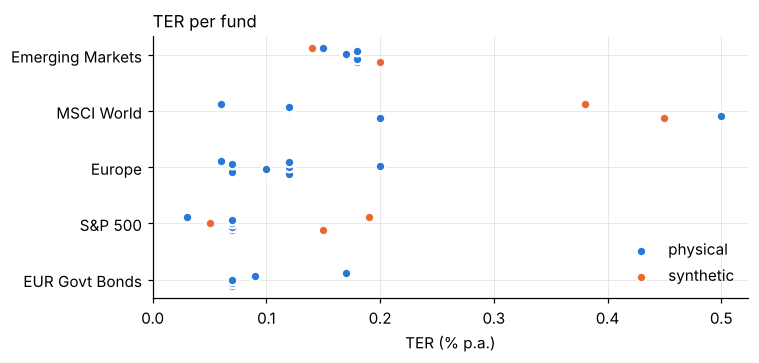

In [4]:
order = df.groupby("index_cluster")["ter_pct"].median().sort_values().index
fig, ax = plt.subplots(figsize=(7, 3.4))
for i, cluster in enumerate(order):
    sub = df[df["index_cluster"] == cluster]
    for rep, s in sub.groupby("replication"):
        jitter = np.linspace(-0.12, 0.12, len(s)) if len(s) > 1 else [0]
        ax.scatter(s["ter_pct"], i + np.array(jitter), s=40, color=COLORS[rep], label=rep,
                   edgecolor="white", linewidth=1.5, zorder=3)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("TER (% p.a.)")
ax.set_xlim(0, None)
handles, labels = ax.get_legend_handles_labels()
ax.legend(dict(zip(labels, handles)).values(), dict(zip(labels, handles)).keys(), frameon=False, loc="lower right")
ax.set_title("TER per fund", loc="left", fontsize=11)
plt.tight_layout()

- Bond, S&P 500 and European funds are the cheapest groups (median TER 0.07-0.10%), emerging markets the most expensive.
- The expensive outliers are older products: the two MSCI World **swap** ETFs (0.38%, 0.45%) and the iShares MSCI World Dist (IWRD, 0.50%), which tracks the same index as iShares Core MSCI World (SWDA, 0.20%).
- Fund size and TER are only weakly related here (Spearman correlation below).

In [5]:
size = df[["ter_pct", "fund_aum_m"]].dropna()
print(f"n = {len(size)}, Spearman(TER, fund size) = {size.corr(method='spearman').iloc[0, 1]:.2f}")

n = 25, Spearman(TER, fund size) = -0.21


## 2. Tracking difference

Tracking difference (TD) = fund return minus benchmark return, here over 5 years, annualised.
The fund return is already net of fees, so TD is the full cost (or gain) for the investor compared to the index.
It can be split into two parts: **TD = -TER + other effects**. If the fee were the only effect, TD would be about minus the TER.
`other_effects = TD + TER` is everything except the fee: withholding tax differences, securities lending income, trading costs, cash drag.

One remaining extraction error gives an impossible value (|TD| > 1% p.a. for an index fund), it is excluded below.

In [6]:
print("excluded:", df.loc[df["td_5y"].abs() > 1, ["ticker", "fund_5y_ann", "benchmark_5y_ann", "td_5y"]].to_dict("records"))
td = df[df["td_5y"].abs() <= 1].copy()
td["asset_class"] = np.where(td["index_cluster"] == "EUR Govt Bonds", "bonds", "equity")

summary = td.groupby("index_cluster").agg(funds=("ticker", "count"), avg_ter=("ter_pct", "mean"), avg_td=("td_5y", "mean"))
summary["other_effects"] = summary["avg_td"] + summary["avg_ter"]
summary.sort_values("other_effects")

excluded: [{'ticker': 'VUSA', 'fund_5y_ann': 13.48, 'benchmark_5y_ann': 14.76, 'td_5y': -1.2799999999999994}]


,funds,avg_ter,avg_td,other_effects
index_cluster,,,,
EUR Govt Bonds,3,0.08,-0.05,0.02
Emerging Markets,7,0.17,-0.07,0.10
MSCI World,5,0.26,-0.04,0.23
S&P 500,5,0.09,0.21,0.30
Europe,6,0.10,0.28,0.38


bonds: n = 3, corr(TER, TD) = -0.90
equity: n = 23, corr(TER, TD) = -0.75


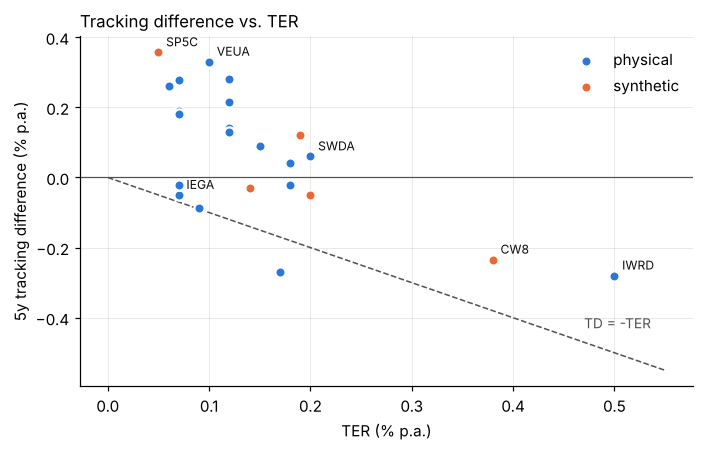

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for rep, s in td.groupby("replication"):
    ax.scatter(s["ter_pct"], s["td_5y"], s=45, color=COLORS[rep], label=rep, edgecolor="white", linewidth=1.5, zorder=3)
x = np.linspace(0, 0.55, 10)
ax.plot(x, -x, color="#52514e", linewidth=1, linestyle="--", zorder=2)
ax.text(0.47, -0.43, "TD = -TER", color="#52514e", fontsize=9)
ax.axhline(0, color="#52514e", linewidth=0.8)
for _, r in td[td["ticker"].isin(["IWRD", "SWDA", "CW8", "SP5C", "IEGA", "VEUA"])].iterrows():
    ax.annotate(r["ticker"], (r["ter_pct"], r["td_5y"]), xytext=(5, 4), textcoords="offset points", fontsize=8, color="#0b0b0b")
ax.set_xlabel("TER (% p.a.)")
ax.set_ylabel("5y tracking difference (% p.a.)")
ax.set_title("Tracking difference vs. TER", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()

for cls, s in td.groupby("asset_class"):
    print(f"{cls}: n = {len(s)}, corr(TER, TD) = {s['ter_pct'].corr(s['td_5y']):.2f}")

- **Bonds** sit almost exactly on the TD = -TER line: no dividends, so cost is the only drag.
- **Equity funds** mostly sit *above* the line, many even beat their index. The benchmarks are *net* indices that assume the maximum dividend withholding tax. Irish funds pay less on US dividends thanks to tax treaties, and securities lending adds a little income. The effect is largest in **Europe** (other effects about +0.38% p.a.).
- Within equities, TER still explains a lot of the cross-section: the more expensive the fund, the lower the TD.
- Note: Vanguard Acc and Dist share classes of the same fund appear as two points with identical values.

### S&P 500: physical vs. swap

In [8]:
td[td["index_cluster"] == "S&P 500"][["ticker", "issuer", "replication", "ter_pct", "td_5y"]].sort_values("td_5y", ascending=False)

,ticker,issuer,replication,ter_pct,td_5y
14,SP5C,Amundi,synthetic,0.05,0.36
10,IUSA,iShares,physical,0.07,0.19
9,CSPX,iShares,physical,0.07,0.18
11,VUAA,Vanguard,physical,0.07,0.18
16,SPXS,UBS,synthetic,0.19,0.12


The Amundi swap ETF has the highest TD. A swap-based fund receives the index's *total* return from the counterparty, so it avoids the US withholding tax on dividends completely, while a physical Irish fund still pays 15%.
The UBS swap ETF does not show the same advantage, its TER is higher (0.19%). With only two swap funds this is an observation, not a result.

## 3. Same index, different price

In [9]:
columns= ["ticker", "issuer", "replication", "ter_pct", "td_5y", "benchmark", "fund_aum_m"]

df[df["index_cluster"] == "MSCI World"][columns].sort_values("ter_pct")

,ticker,issuer,replication,ter_pct,td_5y,benchmark,fund_aum_m
8,UC5,UBS,physical,0.06,NaN,MSCI World Total Return Net,NaN
3,VEVE,Vanguard,physical,0.12,0.13,FTSE Developed Index,NaN
7,MWRD,Amundi,physical,0.12,NaN,MSCI WORLD,19167.55
2,VHVE,Vanguard,physical,0.12,0.14,FTSE Developed Index,NaN
4,XDWD,Xtrackers,physical,0.12,NaN,MSCI Total Return Net World Index,30970.00
0,SWDA,iShares,physical,0.20,0.06,MSCI World Index (Net),NaN
6,CW8,Amundi,synthetic,0.38,-0.23,MSCI WORLD,7199.85
5,XMWO,Xtrackers,synthetic,0.45,NaN,MSCI Total Return Net World Index,14540.00
1,IWRD,iShares,physical,0.50,-0.28,MSCI World Index (Net),9412.39


IWRD and SWDA are both iShares funds on the MSCI World index. IWRD costs 0.30% more per year and its TD is 0.34% lower, almost exactly the fee difference.

## 4. Index choice: FTSE vs. MSCI Emerging Markets

FTSE classifies South Korea as a developed market, MSCI as an emerging market. The extracted top holdings show it.

In [10]:
em = df[df["index_cluster"] == "Emerging Markets"]
cols = ["ticker", "benchmark", "fund_5y_ann",
        "holding_1", "weight_1", "holding_2", "weight_2", "holding_3", "weight_3"]
em[cols].sort_values("benchmark")

,ticker,benchmark,fund_5y_ann,holding_1,weight_1,holding_2,weight_2,holding_3,weight_3
19,VFEA,FTSE Emerging Index,6.58,Taiwan Semiconductor Manufacturing Co. Ltd.,17.90,Tencent Holdings Ltd.,3.20,Alibaba Group Holding Ltd.,2.40
20,VFEM,FTSE Emerging Index,6.58,Taiwan Semiconductor Manufacturing Co. Ltd.,17.90,Tencent Holdings Ltd.,3.20,Alibaba Group Holding Ltd.,2.40
22,AEEM,MSCI Emerging Markets,9.33,TAIWAN SEMICONDUCTOR MANUFACTURING CORP,15.58,SAMSUNG ELECTRONICS CO LTD,7.66,SK HYNIX INC,5.86
17,IEEM,MSCI Emerging Markets Index (Net),8.92,TAIWAN SEMICONDUCTOR MANUFACTURING,15.54,SAMSUNG ELECTRONICS LTD,7.51,SK HYNIX,5.87
18,EIMI,MSCI Emerging Markets Investable Market Index ...,8.80,TAIWAN SEMICONDUCTOR MANUFACTURING,13.68,SAMSUNG ELECTRONICS LTD,6.61,SK HYNIX,5.16
23,EMMUSA,MSCI Emerging Markets Total Return Net,9.03,Taiwan Semiconductor Manufacturing Co Ltd,15.63,Samsung Electronics Co Ltd,8.50,SK Hynix Inc,5.90
24,EMMSF,MSCI Emerging Markets Total Return Net,8.91,TAIWAN SEMICONDUCTOR MFG,15.63,SAMSUNG ELECTRONICS CO,7.55,SK HYNIX,5.90
21,XMME,MSCI Total Return Net Emerging Markets Index,NaN,TAIWAN SEMICONDUCTOR MANUFACTURING,15.49,SAMSUNG ELECTRONICS LTD,7.48,SK HYNIX,5.79


All MSCI funds have the same top 3: TSMC, Samsung Electronics and SK Hynix. Samsung and SK Hynix alone are about 13% of MSCI EM.
In the FTSE index (Vanguard) the #2 and #3 are Tencent and Alibaba with only 3.2% and 2.4%: FTSE classifies South Korea as a developed market, so Korean companies are not in the index at all.

Over 5 years the FTSE funds returned 6.6% p.a. against about 9% for the MSCI funds. Korea is the most visible difference, not the only one (the weights of China, India and Taiwan also differ between the two indices).
Two "emerging markets" ETFs can hold quite different portfolios: the index methodology is part of the investment decision.

## 5. Concentration

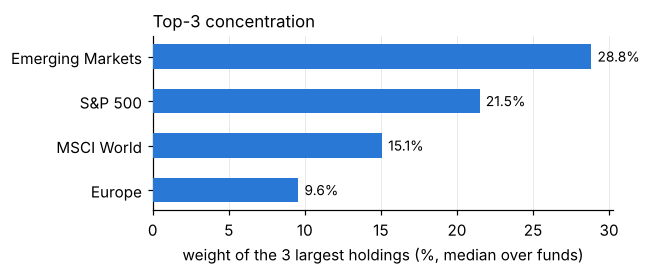

In [11]:
equity = df[df["index_cluster"] != "EUR Govt Bonds"]
conc = equity.groupby("index_cluster")["top3_weight"].median().sort_values()
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(conc.index, conc.values, color="#2a78d6", height=0.55, zorder=3)
for i, v in enumerate(conc.values):
    ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("weight of the 3 largest holdings (%, median over funds)")
ax.set_title("Top-3 concentration", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout()

- Emerging markets is the most concentrated group, mostly because of TSMC (15-18%).
- The S&P 500 top 3 (NVIDIA, Apple, Microsoft) are more than a fifth of the index, "MSCI World" is still about 15% in the same three US stocks.
- Bond funds are left out: some issuers list single bonds, others list countries, so the numbers are not comparable.

## Limitations

- 39 funds, one factsheet date (end of September 2026, two UBS factsheets end of August). Small groups, no statistical tests beyond correlations.
- The data is extracted, not hand-checked. On the labelled funds the extractor was about 92% correct, about 97% for values that were not flagged. Some errors remain (one is excluded above).
- Flagged values are dropped, so some funds are missing from some comparisons. The peer check also dropped a few correct EM 1y returns, because FTSE/MSCI and USD/EUR funds were in the same peer group.
- Returns are in each share class currency (Amundi EM and MSCI World swap are in EUR).